# Music source separation experiments

Compare vocal and accompaniment separation with Spleeter, Demucs and Open-Unmix. Place a track at `song.mp3` and install the corresponding packages and model weights before running their cells. Results and audio are written to `separation_results/`.

SDR/SIR/SAR require separate reference stems; they cannot be measured from the mixture alone. The simplified Wave-U-Net cell defines an experimental architecture but does not run inference because no compatible trained checkpoint is provided. The spectral correlation at the end is descriptive and does not measure separation quality or leakage. Saved outputs are from an earlier run and have not been regenerated after these corrections.

Embedded audio previews are limited to the first five seconds to keep the notebook manageable; generated WAV files retain their full duration.

**Data:** No fixed dataset. Supply a local recording as `song.mp3`; the evaluation cells also need separate reference stems when calculating separation metrics.

In [ ]:
# Install Spleeter, Demucs, Open-Unmix and mir_eval in a compatible environment
# before running their cells. The Wave-U-Net example below does not clone or
# install a repository automatically.

---
## Загрузка и подготовка аудио

In [1]:
import os
import numpy as np
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display

INPUT_AUDIO  = 'song.mp3'       # путь к вашему треку
VOCALS_REF   = None              # путь к эталонным вокалам (если есть, напр. из MUSDB18)
ACCOMP_REF   = None              # путь к эталонному аккомпанементу (если есть)
OUTPUT_DIR   = 'separation_results'
SAMPLE_RATE  = 44100
DURATION     = 60                # обрабатываем первые N секунд (None = весь трек)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Загрузка микса
mixture, sr = librosa.load(INPUT_AUDIO, sr=SAMPLE_RATE, mono=False,
                            duration=DURATION)
if mixture.ndim == 1:
    mixture = np.stack([mixture, mixture])  # моно → стерео

print(f' Загружен трек: {INPUT_AUDIO}')
print(f'   Sample rate : {sr} Hz')
print(f'   Duration    : {mixture.shape[1]/sr:.1f} сек')
print(f'   Shape       : {mixture.shape}  (channels × samples)')

# Сохраняем wav для моделей
MIX_WAV = os.path.join(OUTPUT_DIR, 'mixture.wav')
sf.write(MIX_WAV, mixture.T, sr)

# Загрузка эталона (если есть)
vocals_ref, accomp_ref = None, None
if VOCALS_REF:
    vocals_ref, _ = librosa.load(VOCALS_REF, sr=SAMPLE_RATE, mono=False, duration=DURATION)
    if vocals_ref.ndim == 1: vocals_ref = np.stack([vocals_ref, vocals_ref])
if ACCOMP_REF:
    accomp_ref, _ = librosa.load(ACCOMP_REF, sr=SAMPLE_RATE, mono=False, duration=DURATION)
    if accomp_ref.ndim == 1: accomp_ref = np.stack([accomp_ref, accomp_ref])

print('\n🎧 Воспроизведение микса:')
display(Audio(mixture[:, :5 * sr], rate=sr))

/opt/miniconda3/envs/Lesson_46/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


 Загружен трек: song.mp3
   Sample rate : 44100 Hz
   Duration    : 60.0 сек
   Shape       : (2, 2646000)  (channels × samples)

🎧 Воспроизведение микса:


---
## Вспомогательные функции

In [2]:
import mir_eval
import warnings
warnings.filterwarnings('ignore')

results_table = {}  # итоговое хранилище метрик

def compute_metrics(est_vocals, est_accomp, ref_vocals=None, ref_accomp=None):
    """Считает SDR/SIR/SAR через mir_eval (BSS Eval).
    Возвращает словарь с метриками или None если нет эталона."""
    if ref_vocals is None or ref_accomp is None:
        return None
    # Trim every stem before stacking; preserve the fixed vocal/accompaniment order.
    stems = [ref_vocals.mean(0), ref_accomp.mean(0), est_vocals.mean(0), est_accomp.mean(0)]
    length = min(len(stem) for stem in stems)
    if length == 0:
        raise ValueError("Reference and estimated stems must be non-empty.")
    reference = np.stack([stem[:length] for stem in stems[:2]])
    estimated = np.stack([stem[:length] for stem in stems[2:]])
    sdr, sir, sar, _ = mir_eval.separation.bss_eval_sources(reference, estimated, compute_permutation=False)
    return {
        'SDR_vocals': round(float(sdr[0]), 2),
        'SIR_vocals': round(float(sir[0]), 2),
        'SAR_vocals': round(float(sar[0]), 2),
        'SDR_accomp': round(float(sdr[1]), 2),
    }

def plot_spectrograms(mixture, vocals, accomp, model_name, sr=44100):
    """Рисует спектрограммы микса, вокала и аккомпанемента."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    fig.suptitle(f'Спектрограммы — {model_name}', fontsize=14, fontweight='bold')
    for ax, signal, title in zip(
        axes,
        [mixture.mean(0), vocals.mean(0), accomp.mean(0)],
        ['Mixture (вход)', 'Vocals (вокал)', 'Accompaniment (минус)']
    ):
        D = librosa.amplitude_to_db(np.abs(librosa.stft(signal)), ref=np.max)
        img = librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='log', ax=ax, cmap='magma')
        ax.set_title(title)
        fig.colorbar(img, ax=ax, format='%+2.0f dB')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'{model_name}_spectrograms.png'), dpi=100)
    plt.show()

def save_and_play(vocals, accomp, model_name, sr=44100):
    """Сохраняет wav и выводит плееры."""
    v_path = os.path.join(OUTPUT_DIR, f'{model_name}_vocals.wav')
    a_path = os.path.join(OUTPUT_DIR, f'{model_name}_accomp.wav')
    sf.write(v_path, vocals.T, sr)
    sf.write(a_path, accomp.T, sr)
    print(f'🎤 Вокал ({model_name}):')
    display(Audio(vocals[:, :5 * sr], rate=sr))
    print(f'🎸 Аккомпанемент ({model_name}):')
    display(Audio(accomp[:, :5 * sr], rate=sr))
    return v_path, a_path

def report_metrics(metrics, model_name):
    if metrics:
        print(f'\n📊 Метрики [{model_name}]:')
        for k, v in metrics.items():
            print(f'   {k:15s}: {v:6.2f} dB')
        results_table[model_name] = metrics
    else:
        print('\nℹ️  Эталонные треки не заданы — объективные метрики недоступны.')
        results_table[model_name] = {}

print('Вспомогательные функции загружены.')

Вспомогательные функции загружены.


---
## Модель 1: Spleeter (Deezer)

In [ ]:
import time

MODEL_NAME = 'Spleeter'
print(f'⏳ Запуск {MODEL_NAME}...')
t0 = time.time()

from spleeter.separator import Separator
from spleeter.audio.adapter import AudioAdapter

# 2stems = vocals + accompaniment
separator = Separator('spleeter:2stems')
audio_loader = AudioAdapter.default()

waveform, _ = audio_loader.load(MIX_WAV, sample_rate=SAMPLE_RATE)
prediction = separator.separate(waveform)

# prediction → dict {'vocals': ndarray, 'accompaniment': ndarray}  shape: (samples, 2)
spleeter_vocals = prediction['vocals'].T          # → (2, samples)
spleeter_accomp = prediction['accompaniment'].T

elapsed = time.time() - t0
print(f'✅ {MODEL_NAME} завершён за {elapsed:.1f} сек')

# Визуализация
plot_spectrograms(mixture, spleeter_vocals, spleeter_accomp, MODEL_NAME, sr)

# Прослушивание
save_and_play(spleeter_vocals, spleeter_accomp, MODEL_NAME, sr)

# Метрики
metrics = compute_metrics(spleeter_vocals, spleeter_accomp, vocals_ref, accomp_ref)
report_metrics(metrics, MODEL_NAME)
results_table[MODEL_NAME]['time_sec'] = round(elapsed, 1)

---
## Модель 2: Demucs (Meta AI)

⏳ Запуск Demucs...
   Устройство: mps


  0%|                                                                                  | 0.0/64.35 [00:00<?, ?seconds/s]Error processing line 1 of /opt/miniconda3/envs/Lesson_46/lib/python3.10/site-packages/distutils-precedence.pth:

  Traceback (most recent call last):
    File "/opt/miniconda3/envs/Lesson_46/lib/python3.10/site.py", line 195, in addpackage
      exec(line)
    File "<string>", line 1, in <module>
  ModuleNotFoundError: No module named '_distutils_hack'

Remainder of file ignored
100%|████████████████████████████████████████████████████████████████████████| 64.35/64.35 [00:20<00:00,  3.20seconds/s]


   Стемы: ['drums', 'bass', 'other', 'vocals']
✅ Demucs завершён за 21.8 сек


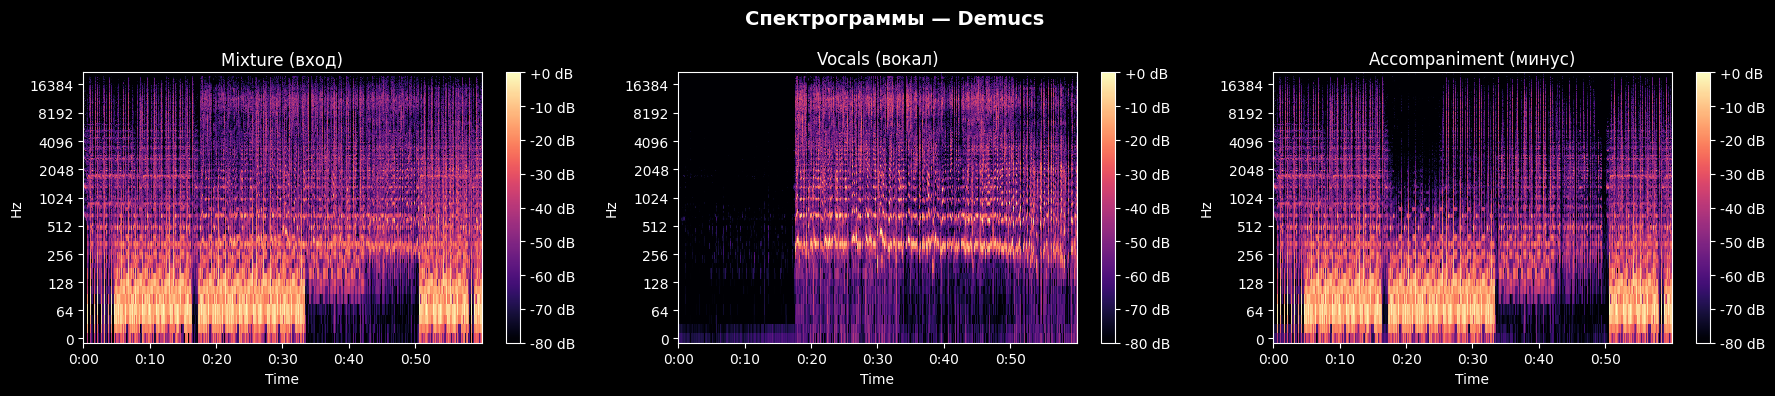

🎤 Вокал (Demucs):


🎸 Аккомпанемент (Demucs):



ℹ️  Эталонные треки не заданы — объективные метрики недоступны.


In [3]:
import torch
import torchaudio
import time

MODEL_NAME = 'Demucs'
print(f'⏳ Запуск {MODEL_NAME}...')
t0 = time.time()

from demucs.pretrained import get_model
from demucs.apply import apply_model

device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print(f'   Устройство: {device}')

model = get_model('htdemucs')   # htdemucs — лучшая версия Demucs
model.to(device)
model.eval()

# Загружаем аудио как tensor (2, samples) без torchaudio.load (чтобы не требовался torchcodec)
audio_np, file_sr = librosa.load(MIX_WAV, sr=None, mono=False)
if audio_np.ndim == 1:
    audio_np = np.stack([audio_np, audio_np], axis=0)
wav = torch.from_numpy(audio_np).float()
if file_sr != model.samplerate:
    import scipy.signal as sig
    n_out = int(wav.shape[1] * model.samplerate / file_sr)
    wav = torch.from_numpy(np.array([sig.resample(wav[c].numpy(), n_out) for c in range(2)])).float()

wav = wav.to(device).unsqueeze(0)  # → (1, 2, samples)

with torch.no_grad():
    sources = apply_model(model, wav, device=device, progress=True)[0]  # (4, 2, samples)

# Demucs htdemucs: drums, bass, other, vocals
source_names = model.sources
print(f'   Стемы: {source_names}')
idx_vocals = source_names.index('vocals')

demucs_vocals = sources[idx_vocals].cpu().numpy()          # (2, samples)
# Аккомпанемент = сумма всех остальных стемов
other_idxs = [i for i in range(len(source_names)) if i != idx_vocals]
demucs_accomp = sum(sources[i].cpu().numpy() for i in other_idxs)

elapsed = time.time() - t0
print(f'✅ {MODEL_NAME} завершён за {elapsed:.1f} сек')

# Ресэмплируем если нужно
if model.samplerate != sr:
    import scipy.signal as sig
    ratio = sr / model.samplerate
    n_out = int(demucs_vocals.shape[1] * ratio)
    demucs_vocals = np.array([sig.resample(demucs_vocals[c], n_out) for c in range(2)])
    demucs_accomp = np.array([sig.resample(demucs_accomp[c], n_out) for c in range(2)])

plot_spectrograms(mixture, demucs_vocals, demucs_accomp, MODEL_NAME, sr)
save_and_play(demucs_vocals, demucs_accomp, MODEL_NAME, sr)

metrics = compute_metrics(demucs_vocals, demucs_accomp, vocals_ref, accomp_ref)
report_metrics(metrics, MODEL_NAME)
results_table[MODEL_NAME]['time_sec'] = round(elapsed, 1)

---
## Модель 3: Open-Unmix (UMX-L, pretrained MUSDB18HQ)

Устройство: mps
📥 Загружаем umxl через torch.hub (первый раз — скачает веса)...


Using cache found in ~/.cache/torch/hub/sigsep_open-unmix-pytorch_master


✅ umxl загружен

⏳ Запуск Open-Unmix...
✅ Open-Unmix завершён за 11.4 сек
   Стемы: ['vocals', 'drums', 'bass', 'other']


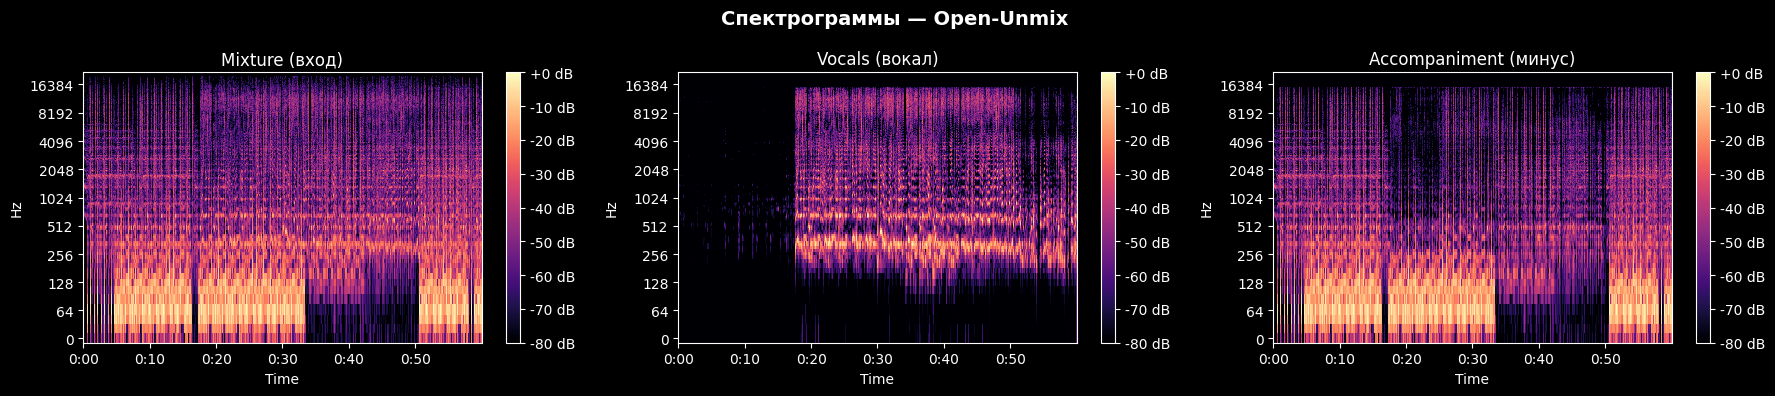

🎤 Вокал (Open-Unmix):


🎸 Аккомпанемент (Open-Unmix):



ℹ️  Эталонные треки не заданы — объективные метрики недоступны.


In [5]:
import os, time, subprocess
import numpy as np
import torch
import soundfile as sf
import warnings
warnings.filterwarnings('ignore')

MODEL_NAME = 'Open-Unmix'
device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print(f'Устройство: {device}')

# ─────────────────────────────────────────────────────────────
# Шаг 1: Установка пакета
# ─────────────────────────────────────────────────────────────
import openunmix  # Install the package before running this cell.

# ─────────────────────────────────────────────────────────────
# Шаг 2: Загрузка pretrained модели через torch.hub
#
# Доступные варианты (меняйте UMX_MODEL):
#   'umxl'  — лучшее качество, обучен на MUSDB18HQ + доп. данные (~400 MB)
#   'umxhq' — только MUSDB18HQ (~130 MB)
#   'umx'   — стандартный MUSDB18 (~130 MB), быстрее
# ─────────────────────────────────────────────────────────────
UMX_MODEL = 'umxl'   # ← меняйте здесь
UMX_SR    = 44100    # sample rate модели

print(f'📥 Загружаем {UMX_MODEL} через torch.hub (первый раз — скачает веса)...')
separator = torch.hub.load(
    'sigsep/open-unmix-pytorch',
    UMX_MODEL,
    device=device,
    pretrained=True
)
separator.eval()
print(f'✅ {UMX_MODEL} загружен')

# ─────────────────────────────────────────────────────────────
# Шаг 3: Inference
# open-unmix ожидает tensor shape (batch, channels, samples)
# Возвращает dict: {'vocals': tensor, 'drums': tensor, 'bass': tensor, 'other': tensor}
# ─────────────────────────────────────────────────────────────
print(f'\n⏳ Запуск {MODEL_NAME}...')
t0 = time.time()

# Ресэмплируем если нужно
mix_for_umx = mixture
if sr != UMX_SR:
    import torchaudio
    t_mix = torch.tensor(mixture, dtype=torch.float32)
    t_mix = torchaudio.functional.resample(t_mix, sr, UMX_SR)
    mix_for_umx = t_mix.numpy()

mix_tensor = torch.tensor(mix_for_umx[None], dtype=torch.float32).to(device)  # (1, 2, L)

with torch.no_grad():
    estimates = separator(mix_tensor)

# Нормализуем формат выхода separator: dict или 4D tensor
if isinstance(estimates, dict):
    estimate_names = list(estimates.keys())
    est_dict = estimates
else:
    if not torch.is_tensor(estimates) or estimates.dim() != 4:
        raise TypeError(f'Неподдерживаемый тип выхода separator: {type(estimates)}')

    # Обычно: (batch, targets, channels, samples) или (targets, batch, channels, samples)
    if estimates.shape[0] == 1:
        est_3d = estimates[0]          # (targets, channels, samples)
    elif estimates.shape[1] == 1:
        est_3d = estimates[:, 0]       # (targets, channels, samples)
    else:
        est_3d = estimates[0]

    estimate_names = list(getattr(separator, 'targets', []))
    if not estimate_names and hasattr(separator, 'target_models'):
        try:
            estimate_names = list(separator.target_models.keys())
        except Exception:
            estimate_names = []
    if not estimate_names:
        raise ValueError("The separator did not provide stem names; cannot identify vocals safely.")

    est_dict = {name: est_3d[i] for i, name in enumerate(estimate_names[:est_3d.shape[0]])}

# Извлекаем вокал
if 'vocals' not in est_dict:
    raise ValueError(f"Open-Unmix did not return a named vocals stem: {list(est_dict)}")
vocals_t = est_dict['vocals']

if vocals_t.dim() == 3:
    vocals_t = vocals_t[0]
umx_vocals = vocals_t.cpu().numpy()          # (2, L)

# Аккомпанемент = сумма всех остальных стемов
non_vocal_keys = [k for k in est_dict.keys() if k != 'vocals']
if non_vocal_keys:
    acc_sum = None
    for k in non_vocal_keys:
        t = est_dict[k]
        if t.dim() == 3:
            t = t[0]
        acc_sum = t if acc_sum is None else acc_sum + t
    umx_accomp = acc_sum.cpu().numpy()
else:
    # Если модель 2stems — аккомпанемент через вычитание
    n = min(umx_vocals.shape[1], mix_for_umx.shape[1])
    umx_accomp = mix_for_umx[:, :n] - umx_vocals[:, :n]

# Выравниваем длины
n = min(umx_vocals.shape[1], umx_accomp.shape[1], mix_for_umx.shape[1])
umx_vocals = umx_vocals[:, :n]
umx_accomp = umx_accomp[:, :n]

# Ресэмплируем обратно если меняли sr
if sr != UMX_SR:
    import torchaudio
    umx_vocals = torchaudio.functional.resample(
        torch.tensor(umx_vocals), UMX_SR, sr).numpy()
    umx_accomp = torchaudio.functional.resample(
        torch.tensor(umx_accomp), UMX_SR, sr).numpy()

elapsed = time.time() - t0
print(f'✅ {MODEL_NAME} завершён за {elapsed:.1f} сек')
print(f'   Стемы: {list(est_dict.keys())}')

# ─────────────────────────────────────────────────────────────
# Шаг 4: Визуализация, прослушивание, метрики
# ─────────────────────────────────────────────────────────────
ref_mix = mixture[:, :umx_vocals.shape[1]]
plot_spectrograms(ref_mix, umx_vocals, umx_accomp, MODEL_NAME, sr)
save_and_play(umx_vocals, umx_accomp, MODEL_NAME, sr)

metrics = compute_metrics(umx_vocals, umx_accomp, vocals_ref, accomp_ref)
report_metrics(metrics, MODEL_NAME)
results_table[MODEL_NAME]['time_sec'] = round(elapsed, 1)

## Wave-U-Net architecture (inference unavailable)

In [ ]:
"""
Wave-U-Net работает напрямую с waveform (без STFT).
Репозиторий: https://github.com/f90/Wave-U-Net-Pytorch
Pretrained веса: https://github.com/f90/Wave-U-Net-Pytorch#pretrained-models
"""

import sys, time
import torch
import torch.nn as nn
import numpy as np

MODEL_NAME = 'Wave-U-Net'

# Добавляем путь к клонированному репозиторию
WAVEUNET_PATH = 'Wave-U-Net-Pytorch'
if WAVEUNET_PATH not in sys.path:
    sys.path.insert(0, WAVEUNET_PATH)

# ── Компактная реализация Wave-U-Net ──────────────────────────
class WaveUNetBlock(nn.Module):
    """Базовый down/up блок для работы с waveform."""
    def __init__(self, in_ch, out_ch, kernel=15, stride=1, transposed=False):
        super().__init__()
        pad = kernel // 2
        if transposed:
            self.conv = nn.ConvTranspose1d(in_ch, out_ch, kernel, stride=stride,
                                           padding=pad, output_padding=stride-1)
        else:
            self.conv = nn.Conv1d(in_ch, out_ch, kernel, stride=stride, padding=pad)
        self.norm = nn.BatchNorm1d(out_ch)
        self.act  = nn.LeakyReLU(0.2)

    def forward(self, x): return self.act(self.norm(self.conv(x)))

class WaveUNet(nn.Module):
    """
    Упрощённый Wave-U-Net с 5 уровнями.
    Входной формат: (B, 2, L) — стерео waveform
    Выходной формат: (B, 2, L) — вокал
    """
    def __init__(self, n_src=2, channels=[24, 48, 72, 96, 128]):
        super().__init__()
        self.encoders, self.decoders = nn.ModuleList(), nn.ModuleList()
        in_ch = n_src
        for out_ch in channels:
            self.encoders.append(WaveUNetBlock(in_ch, out_ch, stride=2))
            in_ch = out_ch
        self.bottleneck = WaveUNetBlock(in_ch, in_ch)
        rev_ch = list(reversed(channels))
        for i, out_ch in enumerate(rev_ch):
            in_dec = in_ch + (rev_ch[i-1] if i > 0 else in_ch)
            self.decoders.append(WaveUNetBlock(in_ch + (rev_ch[i-1] if i>0 else in_ch),
                                               out_ch, stride=2, transposed=True))
            in_ch = out_ch
        self.output_conv = nn.Sequential(
            nn.Conv1d(in_ch + n_src, n_src, 1),
            nn.Tanh()
        )

    def forward(self, x):
        skips = []
        h = x
        for enc in self.encoders:
            h = enc(h)
            skips.append(h)
        h = self.bottleneck(h)
        for dec, skip in zip(self.decoders, reversed(skips)):
            # Выравниваем длины перед concat
            min_l = min(h.shape[2], skip.shape[2])
            h = dec(torch.cat([h[:,:,:min_l], skip[:,:,:min_l]], dim=1))
        min_l = min(h.shape[2], x.shape[2])
        h = torch.cat([h[:,:,:min_l], x[:,:,:min_l]], dim=1)
        return self.output_conv(h)

# This compact architecture has no supplied compatible trained weights.
# Its randomly initialized output is not a valid separation result.
print("Wave-U-Net inference skipped: a compatible trained model is required.")

---
## Итоговое сравнение всех моделей


═══════════════════════════════════════════════════════
        📋 ИТОГОВАЯ ТАБЛИЦА СРАВНЕНИЯ МОДЕЛЕЙ
═══════════════════════════════════════════════════════
     Model  time_sec
    Demucs      21.8
Open-Unmix      11.4
═══════════════════════════════════════════════════════
SDR — Signal-to-Distortion Ratio (выше = лучше)
SIR — Signal-to-Interference Ratio
SAR — Signal-to-Artifacts Ratio


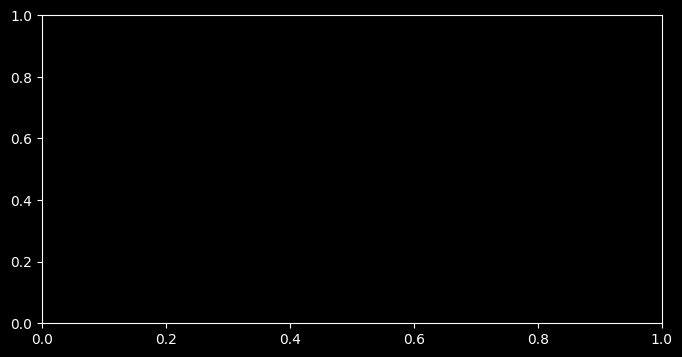

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── Таблица метрик ─────────────────────────────────────────────
df = pd.DataFrame(results_table).T
df.index.name = 'Model'
df = df.reset_index()

print('\n' + '═'*55)
print('        📋 ИТОГОВАЯ ТАБЛИЦА СРАВНЕНИЯ МОДЕЛЕЙ')
print('═'*55)
print(df.to_string(index=False))
print('═'*55)
print('SDR — Signal-to-Distortion Ratio (выше = лучше)')
print('SIR — Signal-to-Interference Ratio')
print('SAR — Signal-to-Artifacts Ratio')

colors = ['#4C72B0', '#55A868', '#C44E52', '#F4A261']

# ── Бар-чарт SDR (если есть метрики) ──────────────────────────
if 'SDR_vocals' in df.columns and df['SDR_vocals'].notna().any():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('Сравнение качества разделения (BSS Eval)', fontsize=14, fontweight='bold')
    colors = ['#4C72B0', '#55A868', '#C44E52', '#F4A261']

    for ax, metric, title in zip(
        axes,
        ['SDR_vocals', 'SDR_accomp'],
        ['SDR — Вокал (dB)', 'SDR — Аккомпанемент (dB)']
    ):
        if metric in df.columns:
            vals = df[metric].astype(float)
            bars = ax.bar(df['Model'], vals, color=colors[:len(df)])
            ax.set_title(title, fontsize=12)
            ax.set_ylabel('dB')
            ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
            for bar, val in zip(bars, vals):
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                        f'{val:.1f}', ha='center', va='bottom', fontsize=10)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'comparison_sdr.png'), dpi=120)
    plt.show()

# ── Время инференса ────────────────────────────────────────────
if 'time_sec' in df.columns:
    fig, ax = plt.subplots(figsize=(8, 4))
    times = df['time_sec'].astype(float)
    bars = ax.barh(df['Model'], times, color=colors[:len(df)])
    ax.set_xlabel('Время (сек)')
    ax.set_title('⏱ Время инференса по моделям', fontsize=12, fontweight='bold')
    for bar, t in zip(bars, times):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                f'{t:.1f}s', va='center', fontsize=10)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'comparison_time.png'), dpi=120)
    plt.show()

print(f'\n✅ Все результаты сохранены в папку: {OUTPUT_DIR}/')

---
## 🎧 Ячейка 8 — Субъективный тест: Side-by-Side прослушивание

In [ ]:
from IPython.display import Audio, display, HTML

print('=' * 55)
print('      🎤 СРАВНЕНИЕ ВОКАЛЬНЫХ ДОРОЖЕК')
print('=' * 55)

stems = {}
if 'spleeter_vocals' in globals(): stems['Spleeter'] = spleeter_vocals
if 'demucs_vocals' in globals(): stems['Demucs'] = demucs_vocals
if 'umx_vocals' in globals(): stems['Open-Unmix'] = umx_vocals
if 'wunet_vocals' in globals(): stems['Wave-U-Net'] = wunet_vocals

for name, audio in stems.items():
    display(HTML(f'<h4>🔵 {name}</h4>'))
    display(Audio(audio[:, :5 * sr], rate=sr))

print('\n' + '=' * 55)
print('      🎸 СРАВНЕНИЕ АККОМПАНЕМЕНТА (МИНУС)')
print('=' * 55)

backs = {}
if 'spleeter_accomp' in globals(): backs['Spleeter'] = spleeter_accomp
if 'demucs_accomp' in globals(): backs['Demucs'] = demucs_accomp
if 'umx_accomp' in globals(): backs['Open-Unmix'] = umx_accomp
if 'wunet_accomp' in globals(): backs['Wave-U-Net'] = wunet_accomp

for name, audio in backs.items():
    display(HTML(f'<h4>🎸 {name}</h4>'))
    display(Audio(audio[:, :5 * sr], rate=sr))

## Spectral correlation between separated stems

In [ ]:
# Spectral similarity describes the outputs; it cannot establish source leakage.
import numpy as np
import librosa
import matplotlib.pyplot as plt

def spectral_correlation(vocals, accompaniment, sample_rate):
    length = min(vocals.shape[-1], accompaniment.shape[-1])
    if length == 0:
        raise ValueError("Stems must be non-empty.")
    v = librosa.feature.melspectrogram(y=vocals[..., :length].mean(axis=0), sr=sample_rate, n_mels=128)
    a = librosa.feature.melspectrogram(y=accompaniment[..., :length].mean(axis=0), sr=sample_rate, n_mels=128)
    x, y = librosa.power_to_db(v).ravel(), librosa.power_to_db(a).ravel()
    return float(np.corrcoef(x, y)[0, 1]) if np.std(x) and np.std(y) else float("nan")

pairs = {}
for name, prefix in [("Spleeter", "spleeter"), ("Demucs", "demucs"), ("Open-Unmix", "umx")]:
    vocals, accompaniment = globals().get(prefix + "_vocals"), globals().get(prefix + "_accomp")
    if vocals is not None and accompaniment is not None:
        pairs[name] = spectral_correlation(vocals, accompaniment, sr)
print("Mel-spectrogram correlations (not a leakage or quality metric):", pairs)
if pairs:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(list(pairs), list(pairs.values()))
    ax.set(ylim=(-1, 1), ylabel="Correlation", title="Spectral correlation between separated stems")
    plt.tight_layout()
    plt.show()